<a href="https://colab.research.google.com/github/Arsen-Almasov/PRAKTIKA/blob/main/customers_dirty_csv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import pandas as pd

# Создаем "грязные" учебные данные
data = {
    'customer_id': [101, 102, 102, 103, 104, None, 106],
    'name': ['  Иван Иванов ', 'Петр Петров', 'Петр Петров', 'мария сидорова', 'Alex Smith', 'Ольга К.', 'Н/Д'],
    'email': ['ivan@mail.ru', 'petr@gmail', 'petr@gmail', 'MARIA@YANDEX.RU', 'alex_smith@', 'olga@mail.ru', 'unknown'],
    'phone': ['+79991112233', '89991112233', '89991112233', '999-111-22-33', '12345', None, 'нет телефона'],
    'registration_date': ['2023-01-15', '15/01/2023', '15/01/2023', '2023.01.15', 'Jan 15, 2023', '2023-01-15', None]
}

df = pd.DataFrame(data)

# Сохраняем в CSV файл
df.to_csv('customer_dirty.csv', index=False)
print("Файл 'customer_dirty.csv' успешно создан и весит больше 0 КБ!")


Файл 'customer_dirty.csv' успешно создан и весит больше 0 КБ!


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("customer_dirty.csv")

print("Размер датасета:", df.shape)

Размер датасета: (7, 5)


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        6 non-null      float64
 1   name               7 non-null      object 
 2   email              7 non-null      object 
 3   phone              6 non-null      object 
 4   registration_date  6 non-null      object 
dtypes: float64(1), object(4)
memory usage: 412.0+ bytes


In [14]:
print("Пропуски в каждом столбце:")
display(df.isnull().sum())

print("Всего пропусков:", df.isnull().sum().sum())

Пропуски в каждом столбце:


,0
customer_id,1
name,0
email,0
phone,1
registration_date,1


Всего пропусков: 3


In [15]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,6.0,NaN,NaN,NaN,103.0,1.788854,101.0,102.0,102.5,103.75,106.0
name,7,6,Петр Петров,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
email,7,6,petr@gmail,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
phone,6,5,89991112233,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
registration_date,6,4,2023-01-15,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Числовые признаки:", numeric_cols)
print("Категориальные признаки:", categorical_cols)

Числовые признаки: ['customer_id']
Категориальные признаки: ['name', 'email', 'phone', 'registration_date']


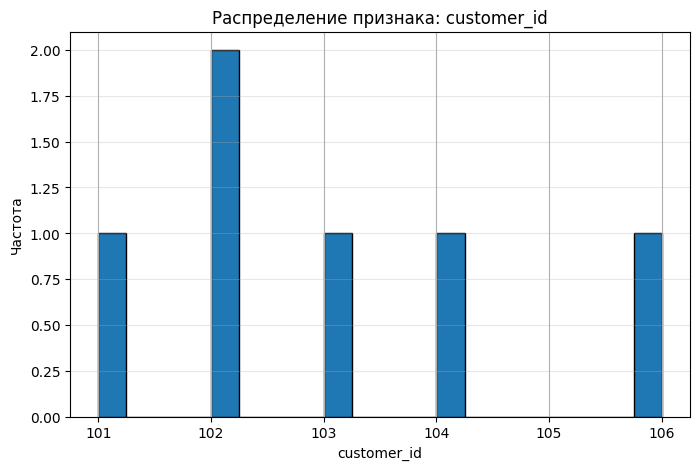

count      6.000000
mean     103.000000
std        1.788854
min      101.000000
25%      102.000000
50%      102.500000
75%      103.750000
max      106.000000
Name: customer_id, dtype: float64


In [17]:
if numeric_cols:
    num_col = numeric_cols[0]

    plt.figure(figsize=(8, 5))
    df[num_col].hist(bins=20, edgecolor="black")
    plt.title(f"Распределение признака: {num_col}")
    plt.xlabel(num_col)
    plt.ylabel("Частота")
    plt.grid(axis="y", alpha=0.3)
    plt.show()

    print(df[num_col].describe())
else:
    print("Числовые признаки не найдены.")

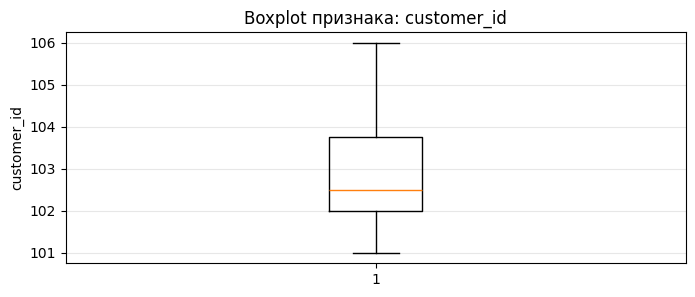

In [18]:
if numeric_cols:
    plt.figure(figsize=(8, 3))
    plt.boxplot(df[num_col].dropna())
    plt.title(f"Boxplot признака: {num_col}")
    plt.ylabel(num_col)
    plt.grid(axis="y", alpha=0.3)
    plt.show()

In [19]:
if numeric_cols:
    q1 = df[num_col].quantile(0.25)
    q3 = df[num_col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df[
        (df[num_col] < lower) | (df[num_col] > upper)
    ]

    print("Признак:", num_col)
    print("Нижняя граница:", lower)
    print("Верхняя граница:", upper)
    print("Количество потенциальных выбросов:", len(outliers))

Признак: customer_id
Нижняя граница: 99.375
Верхняя граница: 106.375
Количество потенциальных выбросов: 0


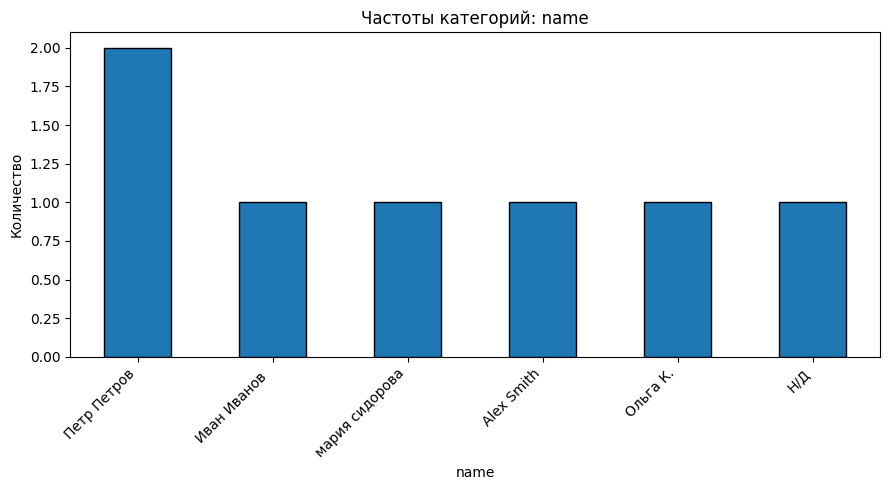

In [20]:
if categorical_cols:
    cat_col = categorical_cols[0]

    counts = (
        df[cat_col]
        .astype("string")
        .fillna("Пропуск")
        .value_counts()
        .head(20)
    )

    plt.figure(figsize=(9, 5))
    counts.plot(kind="bar", edgecolor="black")
    plt.title(f"Частоты категорий: {cat_col}")
    plt.xlabel(cat_col)
    plt.ylabel("Количество")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("Категориальные признаки не найдены.")

In [21]:
# Сводка пропусков
missing = df.isnull().sum()
print("Столбцы с пропусками:")
print(missing[missing > 0])

# Потенциальные выбросы во всех числовых столбцах
print("\nПотенциальные выбросы по методу IQR:")

for col in numeric_cols:
    series = df[col].dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((series < lower) | (series > upper)).sum()

    print(f"{col}: {count}")

Столбцы с пропусками:
customer_id          1
phone                1
registration_date    1
dtype: int64

Потенциальные выбросы по методу IQR:
customer_id: 0
